## Task 1 — Matplotlib و Seaborn

### 1. الفرق بين المكتبتين
Matplotlib تعطيني تحكمًا أكبر في تفاصيل الرسم، مثل المحاور والألوان والعناوين. أما Seaborn فهي مبنية على Matplotlib وتسهّل رسم البيانات الإحصائية بأكواد أقصر. أستخدم Seaborn لإنشاء الرسم، وMatplotlib لتعديل تفاصيله.

### 2. وظيفة hue
تستخدم hue ألوانًا مختلفة لتمييز المجموعات في الرسم.
مثلًا، عند رسم الفاتورة مقابل البقشيش في بيانات tips، أستخدم hue="time" لتمييز الغداء والعشاء، وألاحظ هل العلاقة تختلف بين الوجبتين.

### 3. الخط الأسود في barplot
عند استخدام الإعدادات الافتراضية، يمثل العمود المتوسط، والخط الأسود يمثل فترة الثقة 95% لتقدير المتوسط.
أفحص تداخل فترات الثقة وحجم العينات قبل الحكم على الفرق بين الأيام. الرسم وحده لا يكفي لإثبات أن الفرق دال إحصائيًا.

### 4. قراءة boxplot
الخط داخل الصندوق يمثل الوسيط، وحدّا الصندوق يمثلان الربع الأول والربع الثالث.
المسافة بينهما هي المدى الربيعي IQR، ويساوي Q3 - Q1.
تمتد الشوارب إلى أبعد قيم موجودة ضمن حدود 1.5 × IQR أسفل الربع الأول وأعلى الربع الثالث.
النقاط خارج الشوارب قيم متطرفة محتملة، وأفحصها قبل اتخاذ قرار بحذفها.

## Task 2 — بقشيش المطعم

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### 1. توزيع قيمة الفاتورة حسب الوجبة
أتوقع أن فواتير العشاء تكون أعلى غالبًا من فواتير الغداء.

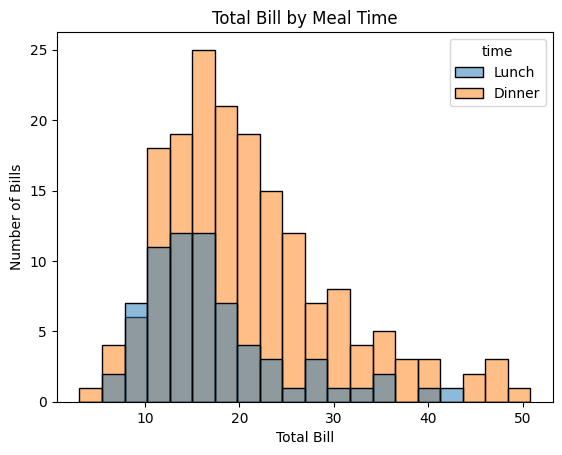

,count,mean,median
time,,,
Lunch,68,17.168676,15.965
Dinner,176,20.797159,18.390


In [2]:
sns.histplot(data=tips, x="total_bill", hue="time",
             multiple="layer", bins=20)

plt.title("Total Bill by Meal Time")
plt.xlabel("Total Bill")
plt.ylabel("Number of Bills")
plt.show()

tips.groupby("time", observed=True)["total_bill"].agg(
    ["count", "mean", "median"]
)

لاحظت أن فواتير العشاء أعلى عمومًا؛ متوسطها 20.80 مقابل 17.17 للغداء، والوسيط 18.39 مقابل 15.97. عدد فواتير العشاء أكبر أيضًا: 176 مقابل 68، لذلك ارتفاع الأعمدة وحده لا يعني أن قيمة الفاتورة أعلى.

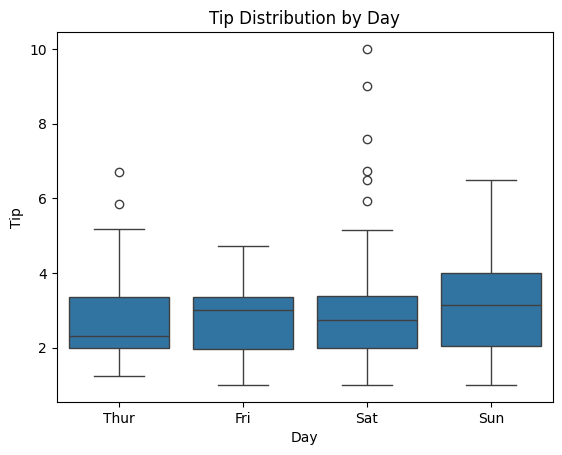

Median tip:
day
Thur    2.305
Fri     3.000
Sat     2.750
Sun     3.150
Name: tip, dtype: float64

Outlier count:
day
Thur    2
Sat     6
dtype: int64


In [3]:
sns.boxplot(data=tips, x="day", y="tip")

plt.title("Tip Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Tip")
plt.show()

print("Median tip:")
print(tips.groupby("day", observed=True)["tip"].median())

q1 = tips.groupby("day", observed=True)["tip"].transform("quantile", q=0.25)
q3 = tips.groupby("day", observed=True)["tip"].transform("quantile", q=0.75)
iqr = q3 - q1

outliers = tips[
    (tips["tip"] < q1 - 1.5 * iqr) |
    (tips["tip"] > q3 + 1.5 * iqr)
]

print("\nOutlier count:")
print(outliers.groupby("day", observed=True).size())

لاحظت أن أعلى وسيط للبقشيش كان يوم الأحد بقيمة 3.15، وأقل وسيط يوم الخميس بقيمة 2.305. يوم السبت كان الأكثر في القيم المتطرفة بعدد 6، مقابل قيمتين يوم الخميس، ولم تظهر قيم متطرفة يومي الجمعة والأحد وفق قاعدة 1.5 × IQR.

### 3. عدد الفواتير حسب اليوم والتدخين
أتوقع أن يكون عدد الفواتير أكبر يوم السبت، وأن تختلف أعداد المدخنين وغير المدخنين بين الأيام.

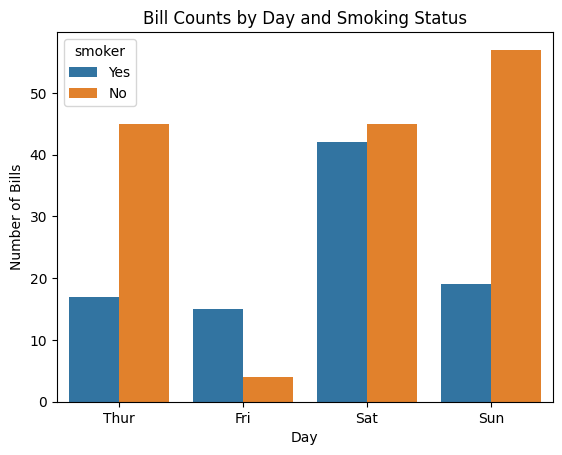

smoker  Yes  No
day            
Thur     17  45
Fri      15   4
Sat      42  45
Sun      19  57


In [4]:
sns.countplot(data=tips, x="day", hue="smoker")

plt.title("Bill Counts by Day and Smoking Status")
plt.xlabel("Day")
plt.ylabel("Number of Bills")
plt.show()

print(tips.groupby(["day", "smoker"], observed=True)
      .size().unstack(fill_value=0))

لاحظت أن السبت سجّل أكبر عدد من الفواتير بإجمالي 87، منها 42 للمدخنين و45 لغير المدخنين. غير المدخنين أكثر في جميع الأيام ما عدا الجمعة؛ إذ بلغ عدد فواتير المدخنين 15 مقابل 4 لغير المدخنين.

### 4. العلاقة بين الفاتورة والبقشيش
أتوقع وجود علاقة طردية؛ كلما ارتفعت قيمة الفاتورة زاد البقشيش غالبًا. سأميّز الوجبة باللون وعدد الأشخاص بحجم النقطة.

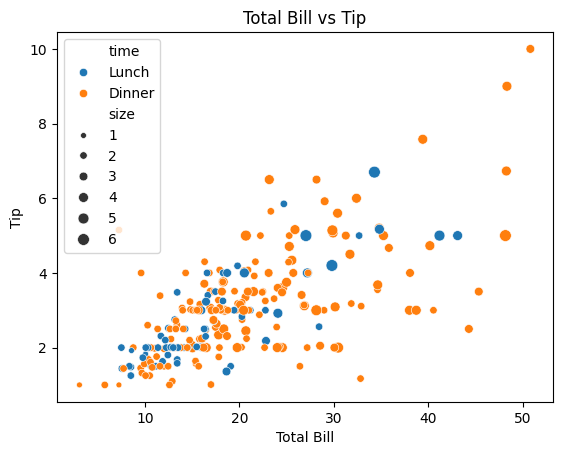

Correlation: 0.676


In [5]:
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="time",
    size="size"
)

plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()

correlation = tips["total_bill"].corr(tips["tip"])
print("Correlation:", round(correlation, 3))

لاحظت وجود علاقة طردية بين قيمة الفاتورة والبقشيش، بمعامل ارتباط 0.676. النقاط تتجه للأعلى عمومًا، لكن توجد فواتير متقاربة في القيمة ويختلف بقشيشها، لذلك قيمة الفاتورة وحدها لا تفسّر كل الاختلاف.

### 5. متوسط البقشيش حسب اليوم
أتوقع أن يكون متوسط البقشيش يوم الأحد أعلى من باقي الأيام، وسأفحص تداخل فترات الثقة قبل تفسير الفرق.

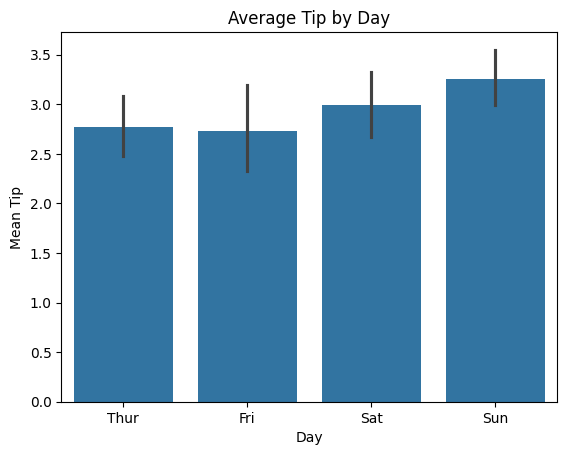

day
Thur    2.771
Fri     2.735
Sat     2.993
Sun     3.255
Name: tip, dtype: float64


In [6]:
sns.barplot(data=tips, x="day", y="tip", seed=7)

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Mean Tip")
plt.show()

print(tips.groupby("day", observed=True)["tip"].mean().round(3))

لاحظت أن الأحد سجّل أعلى متوسط بقشيش بقيمة 3.255، مقابل 2.735 يوم الجمعة. لكن فترات الثقة متداخلة، لذلك لا أجزم من الرسم وحده بأن الفرق دال إحصائيًا، وأحتاج اختبارًا إحصائيًا للتحقق.

### 6. الارتباط بين الفاتورة والبقشيش وعدد الأشخاص
أتوقع وجود ارتباط موجب بين المتغيرات الثلاثة، خصوصًا بين قيمة الفاتورة والبقشيش.

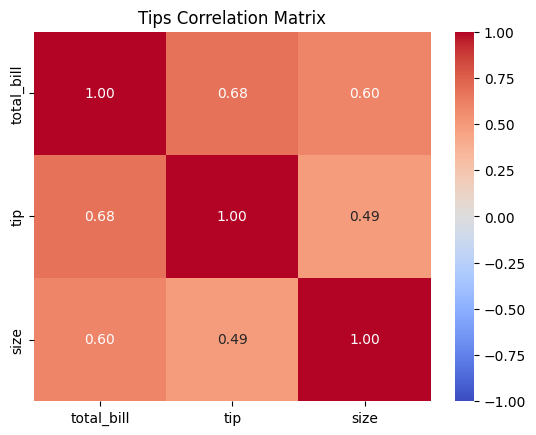

In [7]:
corr = tips[["total_bill", "tip", "size"]].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Tips Correlation Matrix")
plt.show()

لاحظت أن جميع الارتباطات موجبة. أقوى ارتباط بين متغيرين مختلفين كان بين الفاتورة والبقشيش بقيمة 0.68، ثم الفاتورة وعدد الأشخاص بقيمة 0.60، وأخيرًا البقشيش وعدد الأشخاص بقيمة 0.49. هذا يدل على أنها تميل للزيادة معًا، لكنه لا يثبت علاقة سببية.

## Task 3 — القروض بالرسومات

In [8]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving loan_clean.csv to loan_clean.csv


In [9]:
loan = pd.read_csv("loan_clean.csv")

print("Rows and columns:", loan.shape)
print("\nColumn names:")
print(loan.columns.tolist())

display(loan.head())

print("\nLoan status counts:")
print(loan["Loan_Status"].value_counts(dropna=False))

Rows and columns: (614, 13)

Column names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1,Urban,1
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1,Rural,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1,Urban,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1,Urban,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1,Urban,1



Loan status counts:
Loan_Status
1    422
0    192
Name: count, dtype: int64


### 1. عدد الطلبات حسب قرار الموافقة
أتوقع أن يكون عمود الطلبات المقبولة أعلى، بناءً على الأعداد التي ظهرت عند فحص البيانات.

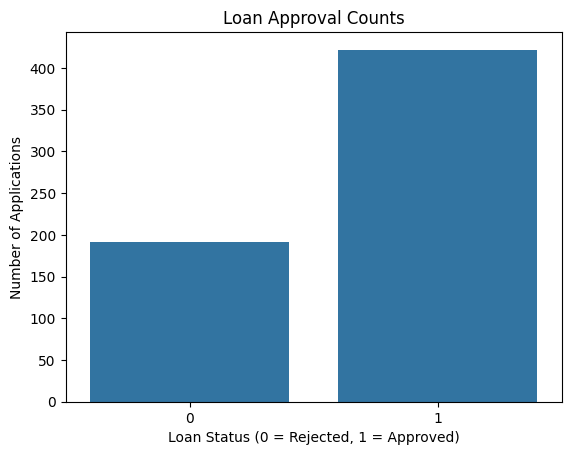

Loan_Status
0    192
1    422
Name: count, dtype: int64
Approval rate: 68.73 %


In [10]:
sns.countplot(data=loan, x="Loan_Status", order=[0, 1])

plt.title("Loan Approval Counts")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Number of Applications")
plt.show()

print(loan["Loan_Status"].value_counts().sort_index())
print("Approval rate:",
      round(loan["Loan_Status"].mean() * 100, 2), "%")

لاحظت أن الطلبات المقبولة أكثر من المرفوضة؛ إذ بلغ عدد المقبولة 422 مقابل 192 مرفوضة، من إجمالي 614 طلبًا. نسبة الموافقة 68.73%، أي نحو ثلثي الطلبات.

### 2. نسبة الموافقة حسب السجل الائتماني والمنطقة
أتوقع ارتفاع نسبة الموافقة لدى أصحاب السجل الائتماني بقيمة 1، وسأقارن أيضًا النسبة بين المناطق.

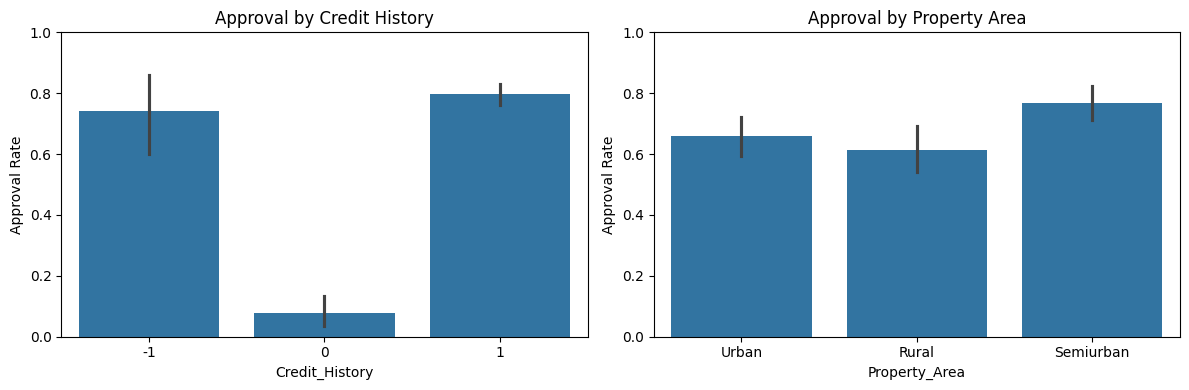

Approval percentage by credit history:
Credit_History
-1    74.00
 0     7.87
 1    79.58
Name: Loan_Status, dtype: float64

Approval percentage by property area:
Property_Area
Rural        61.45
Semiurban    76.82
Urban        65.84
Name: Loan_Status, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    data=loan, x="Credit_History", y="Loan_Status",
    seed=7, ax=axes[0]
)
axes[0].set_title("Approval by Credit History")
axes[0].set_ylabel("Approval Rate")
axes[0].set_ylim(0, 1)

sns.barplot(
    data=loan, x="Property_Area", y="Loan_Status",
    seed=7, ax=axes[1]
)
axes[1].set_title("Approval by Property Area")
axes[1].set_ylabel("Approval Rate")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

print("Approval percentage by credit history:")
print((loan.groupby("Credit_History")["Loan_Status"]
       .mean() * 100).round(2))

print("\nApproval percentage by property area:")
print((loan.groupby("Property_Area")["Loan_Status"]
       .mean() * 100).round(2))

لاحظت فرقًا واضحًا في نسبة الموافقة حسب السجل الائتماني؛ بلغت 79.58% للقيمة 1 مقابل 7.87% للقيمة 0. ظهرت أيضًا فئة بقيمة -1 بنسبة موافقة 74%، وأحتاج مراجعة خطوة التنظيف لمعرفة معنى هذا الترميز.

حسب المنطقة، كانت أعلى نسبة موافقة في Semiurban بقيمة 76.82%، ثم Urban بنسبة 65.84%، وأخيرًا Rural بنسبة 61.45%. هذه مقارنة وصفية ولا تثبت أن المنطقة سبب الموافقة.

### 3. توزيع الدخل ومبلغ القرض حسب قرار الموافقة
سأقارن الوسيط والتشتت بين المقبولين والمرفوضين، وأفحص هل الدخل يميّز بين المجموعتين بوضوح.

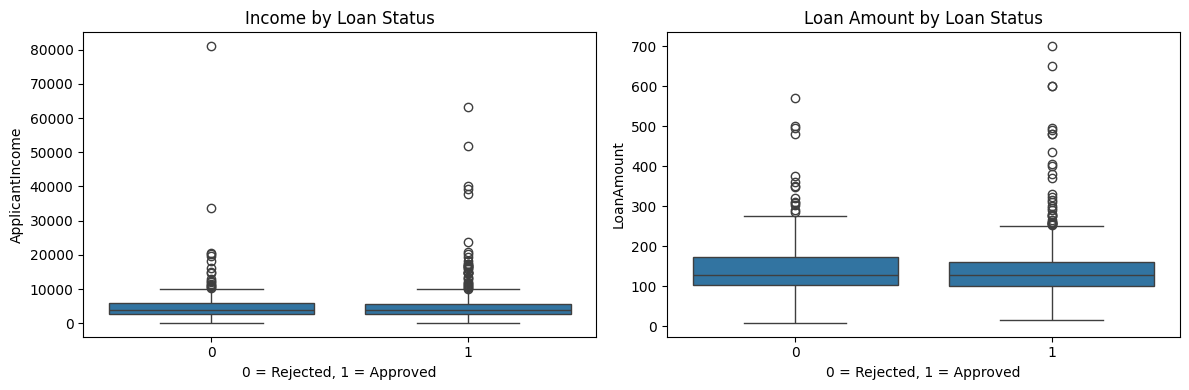

Median income and loan amount:
             ApplicantIncome  LoanAmount
Loan_Status                             
0                     3833.5       128.0
1                     3812.5       128.0


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(
    data=loan, x="Loan_Status",
    y="ApplicantIncome", order=[0, 1], ax=axes[0]
)
axes[0].set_title("Income by Loan Status")
axes[0].set_xlabel("0 = Rejected, 1 = Approved")

sns.boxplot(
    data=loan, x="Loan_Status",
    y="LoanAmount", order=[0, 1], ax=axes[1]
)
axes[1].set_title("Loan Amount by Loan Status")
axes[1].set_xlabel("0 = Rejected, 1 = Approved")

plt.tight_layout()
plt.show()

print("Median income and loan amount:")
print(loan.groupby("Loan_Status")[
    ["ApplicantIncome", "LoanAmount"]
].median())

لاحظت أن وسيط دخل المرفوضين 3833.5، مقابل 3812.5 للمقبولين، وهو فرق بسيط. وسيط مبلغ القرض متساوٍ عند 128 للمجموعتين. يوجد تداخل في التوزيعات وقيم مرتفعة متطرفة؛ لذلك الدخل وحده لا يفصل بوضوح بين المقبولين والمرفوضين.

### 4. توزيع دخل المتقدمين
أتوقع أن تضغط الدخول المرتفعة معظم البيانات في طرف الرسم، وأن يصبح توزيع الدخول الأقل أوضح عند عرض القيم الأقل من 20,000.

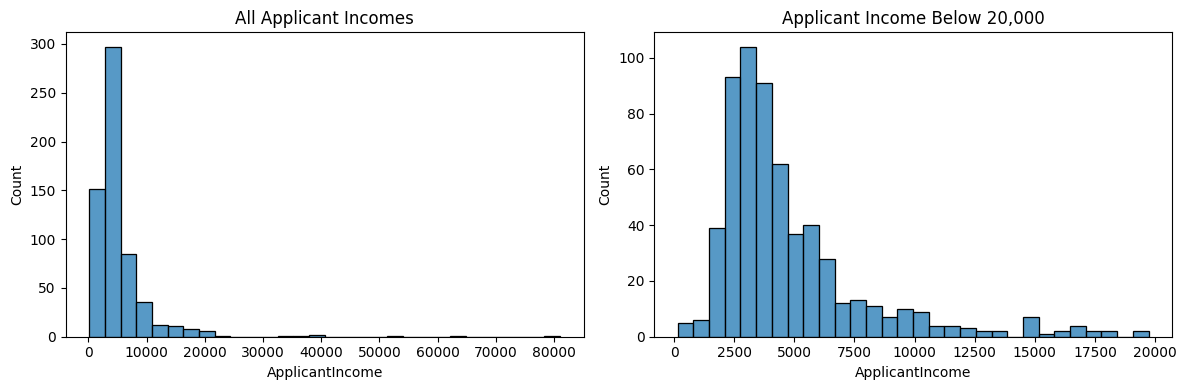

Total applications: 614
Income below 20,000: 602
Income 20,000 or above: 12


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=loan, x="ApplicantIncome",
    bins=30, ax=axes[0]
)
axes[0].set_title("All Applicant Incomes")

income_under_20000 = loan[
    loan["ApplicantIncome"] < 20000
]

sns.histplot(
    data=income_under_20000,
    x="ApplicantIncome",
    bins=30, ax=axes[1]
)
axes[1].set_title("Applicant Income Below 20,000")

plt.tight_layout()
plt.show()

print("Total applications:", len(loan))
print("Income below 20,000:", len(income_under_20000))
print("Income 20,000 or above:",
      (loan["ApplicantIncome"] >= 20000).sum())

لاحظت أن توزيع الدخل منحاز لليمين؛ توجد دخول مرتفعة قليلة تمدّد المحور وتضغط معظم البيانات في الرسم الأول. عند عرض الدخول الأقل من 20,000، ظهر توزيع 602 متقدم بوضوح أكبر، خصوصًا التركز قرب 2,500–5,000. استبعدت 12 حالة من هذا العرض فقط، ولم أحذفها من البيانات الأصلية.

### 5. ارتباط المتغيرات الرقمية بقرار الموافقة
أتوقع أن يكون ارتباط السجل الائتماني بالموافقة أوضح من ارتباط الدخل بها.

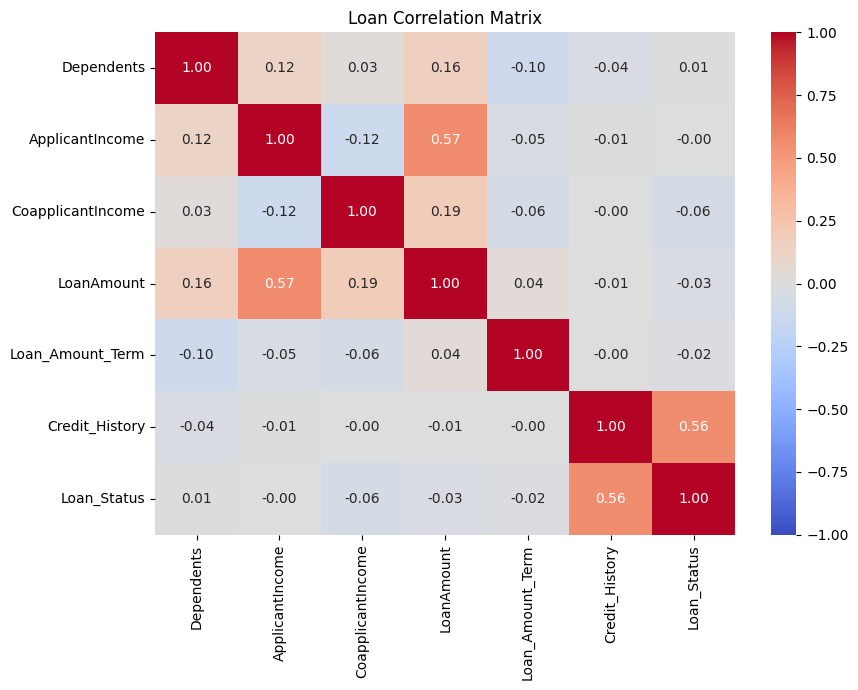

Correlation with loan approval:
Credit_History       0.562
Dependents           0.010
ApplicantIncome     -0.005
Loan_Amount_Term    -0.023
LoanAmount          -0.033
CoapplicantIncome   -0.059
Name: Loan_Status, dtype: float64


In [14]:
numeric_loan = loan.select_dtypes(include="number").copy()

# استبعاد الترميز غير المعروف من حساب الارتباط فقط
numeric_loan["Credit_History"] = numeric_loan[
    "Credit_History"
].where(numeric_loan["Credit_History"].isin([0, 1]))

loan_corr = numeric_loan.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    loan_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Loan Correlation Matrix")
plt.tight_layout()
plt.show()

print("Correlation with loan approval:")
print(loan_corr["Loan_Status"]
      .drop("Loan_Status")
      .sort_values(ascending=False)
      .round(3))

لاحظت أن السجل الائتماني هو الأكثر ارتباطًا بقرار الموافقة بين الأعمدة الرقمية، بمعامل 0.562، بعد استبعاد الترميز -1 من حساب ارتباطه. أما دخل المتقدم فارتباطه قريب من الصفر بقيمة -0.005، وكذلك بقية المتغيرات ارتباطاتها ضعيفة. هذا يصف العلاقة في البيانات ولا يثبت السببية.

### 6. ماذا أضافت الرسومات للتحليل؟

أوضحت الرسومات أن الفرق في الموافقة حسب السجل الائتماني أكبر من الفرق الظاهر في الدخل؛ فنسبة الموافقة للسجل 1 بلغت 79.58%، مقابل 7.87% للسجل 0، بينما وسيط الدخل متقارب بين المقبولين والمرفوضين.

أظهر مخطط الصندوق تداخل توزيع الدخل ومبلغ القرض بين المجموعتين، لذلك لا يكفي أي منهما وحده للتمييز بينهما.

كما أوضح المدرج التكراري أن عددًا قليلًا من الدخول المرتفعة يمدّد المحور ويخفي تفاصيل معظم البيانات. عرض الدخول الأقل من 20,000 جعل توزيع 602 متقدم أوضح، مع إبقاء الحالات الـ12 الأخرى في البيانات الأصلية.

## Task 4 — سجل التنانين

In [15]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)
n = 150

species = rng.choice(
    ["Fire", "Ice", "Storm"],
    n,
    p=[0.4, 0.35, 0.25]
)

base_wing = {"Fire": 14, "Ice": 11, "Storm": 18}
base_heat = {"Fire": 900, "Ice": 80, "Storm": 300}

dragons = pd.DataFrame({
    "dragon_id": [f"D{i:03d}" for i in range(n)],
    "species": species,
    "wingspan_m": [
        round(base_wing[s] + rng.normal(0, 2), 1)
        for s in species
    ],
    "fire_temp_c": [
        round(base_heat[s] + rng.normal(0, 60))
        for s in species
    ],
    "age_years": rng.integers(20, 400, n),
})

dragons["weight_t"] = (
    dragons["wingspan_m"] * 0.6
    + rng.normal(0, 0.8, n)
).round(1)

dragons.loc[37, "wingspan_m"] = 140.0

display(dragons.head())
print("Number of dragons:", len(dragons))

,dragon_id,species,wingspan_m,fire_temp_c,age_years,weight_t
0,D000,Ice,11.0,83,58,6.1
1,D001,Storm,16.6,391,232,9.4
2,D002,Storm,17.3,333,130,10.3
3,D003,Fire,12.9,896,170,6.9
4,D004,Fire,14.0,865,83,8.9


Number of dragons: 150


### 1. عدد التنانين حسب النوع
أتوقع أن يكون نوع Fire الأكثر عددًا؛ لأن احتمال اختياره في توليد البيانات أعلى من النوعين الآخرين.

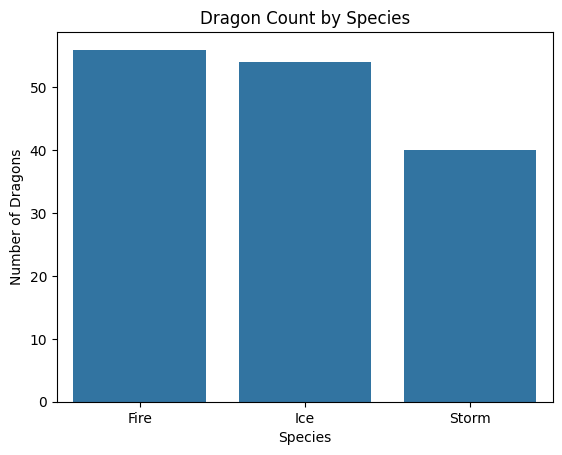

species
Fire     56
Ice      54
Storm    40
Name: count, dtype: int64


In [16]:
sns.countplot(
    data=dragons,
    x="species",
    order=["Fire", "Ice", "Storm"]
)

plt.title("Dragon Count by Species")
plt.xlabel("Species")
plt.ylabel("Number of Dragons")
plt.show()

print(dragons["species"].value_counts())

لاحظت أن Fire الأكثر عددًا بـ56 تنينًا، يليه Ice بـ54، ثم Storm بـ40. الفرق بين Fire وIce بسيط، ومجموع الأنواع 150 تنينًا.

### 2. فحص طول الجناح حسب النوع
أتوقع ظهور القيمة 140 مترًا بعيدة عن بقية الأطوال، وسأفحص سجل التنين قبل تصحيحها.

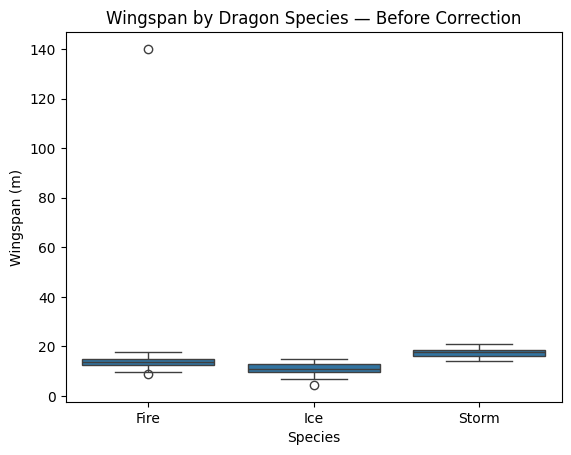

Dragon with the largest wingspan:


,dragon_id,species,wingspan_m,fire_temp_c,age_years,weight_t
37,D037,Fire,140.0,977,231,10.0


Median wingspan by species:
species
Fire     13.85
Ice      11.00
Storm    17.60
Name: wingspan_m, dtype: float64


In [17]:
sns.boxplot(
    data=dragons,
    x="species",
    y="wingspan_m",
    order=["Fire", "Ice", "Storm"]
)

plt.title("Wingspan by Dragon Species — Before Correction")
plt.xlabel("Species")
plt.ylabel("Wingspan (m)")
plt.show()

print("Dragon with the largest wingspan:")
display(dragons.loc[[dragons["wingspan_m"].idxmax()]])

print("Median wingspan by species:")
print(dragons.groupby("species")["wingspan_m"].median())

ظهر التنين D037 بطول جناح 140 مترًا، وهو بعيد جدًا عن بقية نوع Fire. كود المهمة وضع هذه القيمة عمدًا، وقد تمثل خطأ إدخال مثل زيادة صفر، لكن لا يمكن تأكيد القيمة الأصلية من الرسم وحده.

سأعوّضها بوسيط أطوال نوع Fire بعد استبعاد القيمة الخاطئة. هذا تعويض تقديري، مع الاحتفاظ بالبيانات الأصلية.

Original wingspan: 140.0
Estimated replacement: 13.7


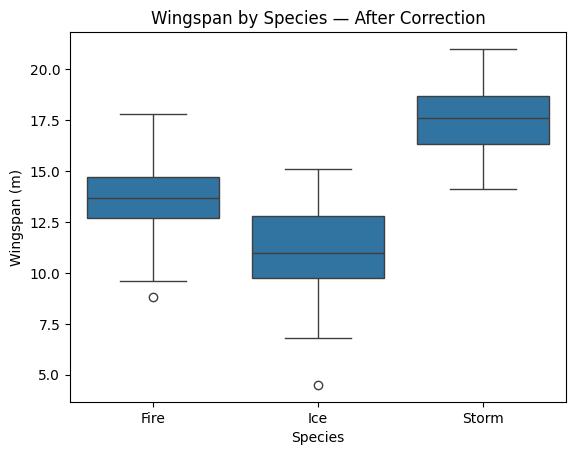

In [18]:
dragons_clean = dragons.copy()

same_species = (
    (dragons["species"] == dragons.loc[37, "species"])
    & (dragons.index != 37)
)

replacement = dragons.loc[
    same_species, "wingspan_m"
].median()

dragons_clean.loc[37, "wingspan_m"] = replacement

print("Original wingspan:", dragons.loc[37, "wingspan_m"])
print("Estimated replacement:", replacement)

sns.boxplot(
    data=dragons_clean,
    x="species",
    y="wingspan_m",
    order=["Fire", "Ice", "Storm"]
)

plt.title("Wingspan by Species — After Correction")
plt.xlabel("Species")
plt.ylabel("Wingspan (m)")
plt.show()

عوّضت طول جناح D037 من 140 إلى 13.7 مترًا، باستخدام وسيط نوع Fire بعد استبعاد السجل نفسه. هذه قيمة تقديرية وليست استعادة للقيمة الأصلية. بعد التصحيح ظهر أن Storm أطول جناحًا عمومًا، ثم Fire، ثم Ice. بقيت بعض النقاط المتطرفة المنخفضة، ولم أحذفها لعدم وجود دليل على خطئها.

### 3. طول الجناح مقابل حرارة النار
أتوقع أن تختلف المجموعات حسب النوع؛ فقد لا يكون النوع الأطول جناحًا هو الأعلى حرارة.

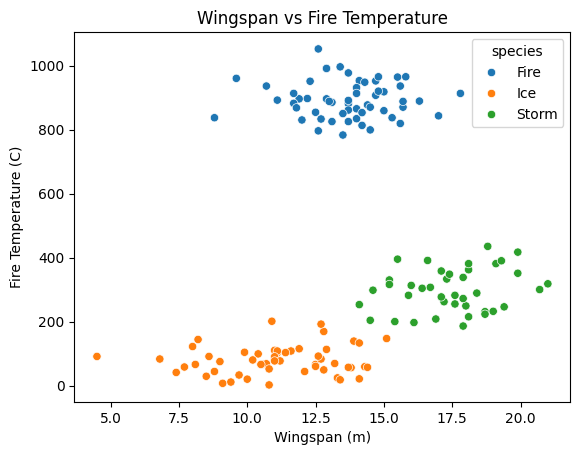

Median wingspan and temperature:
         wingspan_m  fire_temp_c
species                         
Fire           13.7        888.5
Ice            11.0         76.0
Storm          17.6        299.0


In [19]:
sns.scatterplot(
    data=dragons_clean,
    x="wingspan_m",
    y="fire_temp_c",
    hue="species",
    hue_order=["Fire", "Ice", "Storm"]
)

plt.title("Wingspan vs Fire Temperature")
plt.xlabel("Wingspan (m)")
plt.ylabel("Fire Temperature (C)")
plt.show()

print("Median wingspan and temperature:")
print(dragons_clean.groupby("species")[
    ["wingspan_m", "fire_temp_c"]
].median())

لاحظت أن الأنواع تظهر كمجموعات مختلفة. وسيط حرارة Fire هو 888.5 درجة، مقابل 299 لـStorm و76 لـIce. أما وسيط طول الجناح فهو 17.6 مترًا لـStorm، و13.7 لـFire، و11 لـIce. لذلك النوع الأطول جناحًا ليس الأعلى حرارة.

### 4. الارتباط بين خصائص التنانين
أتوقع ارتباطًا قويًا بين طول الجناح والوزن؛ لأن كود توليد البيانات يحسب الوزن اعتمادًا على طول الجناح مع إضافة تغير عشوائي.

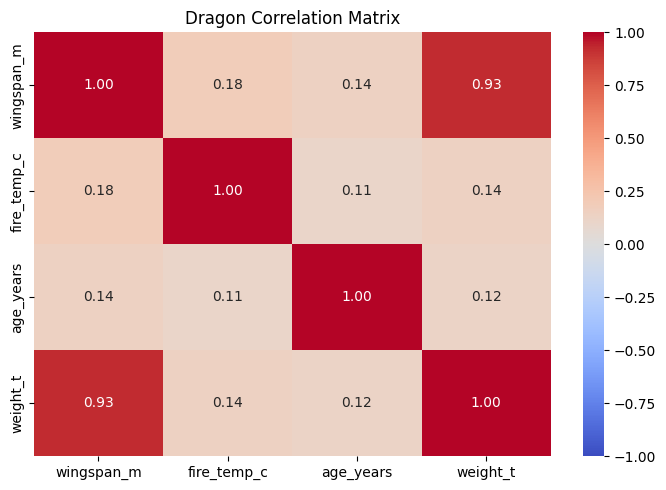

Wingspan and weight correlation: 0.928


In [20]:
dragon_corr = dragons_clean[
    ["wingspan_m", "fire_temp_c", "age_years", "weight_t"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    dragon_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Dragon Correlation Matrix")
plt.tight_layout()
plt.show()

print("Wingspan and weight correlation:",
      round(dragon_corr.loc["wingspan_m", "weight_t"], 3))

لاحظت أن طول الجناح والوزن يحملان معلومات متشابهة بدرجة كبيرة؛ إذ بلغ ارتباطهما 0.928. هذا متوقع لأن الوزن وُلّد اعتمادًا على طول الجناح مع إضافة تغير عشوائي. لكنهما يقيسان خاصيتين مختلفتين، وليسا متطابقين.

### 5. قرار اختيار نوع لتدفئة القرية

أختار نوع Fire لتدفئة القرية؛ لأن الرسم المبعثر أظهر أنه الأعلى حرارة، ووسيط حرارته 888.5 درجة، مقابل 299 لـStorm. كما أن عدده 56 تنينًا، وهو الأكثر توفرًا في السجل.

لن أختار نوع Ice لهذه المهمة؛ لأن وسيط حرارته 76 درجة فقط، وظهر في الرسم ضمن مجموعة الحرارة المنخفضة، مقارنة بالنوعين الآخرين.

اعتمدت في القرار على حرارة النار، وليس طول الجناح؛ فرغم أن Storm الأطول جناحًا بوسيط 17.6 مترًا، فإن حرارته أقل من Fire. هذا اختيار نسبي داخل بيانات التمرين، ولا تتضمن البيانات قياسًا لأمان التدفئة أو كفاءتها.